# Floquet Hamiltonian comparison — PRL appendix style

Plots from `FL_ham.jl` inline comments. Requires three `.npy` files produced by that script:
- `diag_errors.npy` — shape `(6, 2, N)` float64
- `ideal_vs_aod_zeroth.npy` — shape `(4, L, L)` complex128
- `ideal_vs_ideal_full.npy` — shape `(4, L, L)` complex128

In [1]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator

## Configuration
Edit `DATA_DIR` to point to the folder containing your `.npy` files.  
Set `TEXT_USETEX = False` if LaTeX is not installed on your system.

In [2]:
DATA_DIR    = "../data"    # folder containing the .npy files
N_DIAG      = 5     # diagonals to show in Plot 2 (0 = main, 1..N-1 = off-diagonal)
TEXT_USETEX = True  # set False if LaTeX is not installed
SAVE_PDFS   = True  # set False to skip saving and just display inline

k=2

## PRL appendix style + palette

In [3]:
PRL_COL  = 3.375   # single-column width [in]
PRL_2COL = 6.750   # double-column width [in]

PRL_RC = {
    "font.family":           "serif",
    "font.serif":            ["Computer Modern Roman", "Times New Roman", "DejaVu Serif"],
    "text.usetex":           TEXT_USETEX,
    "axes.labelsize":        9,
    "xtick.labelsize":       8,
    "ytick.labelsize":       8,
    "legend.fontsize":       7,
    "axes.linewidth":        0.75,
    "xtick.major.width":     0.75,
    "ytick.major.width":     0.75,
    "xtick.minor.width":     0.5,
    "ytick.minor.width":     0.5,
    "xtick.major.size":      3.5,
    "ytick.major.size":      3.5,
    "xtick.minor.size":      2.0,
    "ytick.minor.size":      2.0,
    "xtick.direction":       "in",
    "ytick.direction":       "in",
    "xtick.top":             True,
    "ytick.right":           True,
    "lines.linewidth":       1.0,
    "figure.dpi":            300,   # lower for notebook display; PDFs save at 300
    "savefig.dpi":           300,
    "savefig.bbox":          "tight",
    "savefig.pad_inches":    0.02,
}
mpl.rcParams.update(PRL_RC)

# Okabe-Ito colorblind-safe palette
PALETTE = [
    "#0072B2",  # blue           → main diagonal / ideal
    "#E69F00",  # orange         → off-diag 1 / AOD single-drive
    "#009E73",  # bluish-green   → off-diag 2 / AOD two-drive
    "#D55E00",  # vermillion     → off-diag 3
    "#CC79A7",  # reddish-purple → off-diag 4
    "#56B4E9",  # sky blue       → off-diag 5
]
LINESTYLES  = ["-", "--", "-.", ":", (0, (3,1,1,1)), (0, (5,1))]
DIAG_LABELS = ["Main diagonal"] + [rf"Off-diagonal $j={j}$" for j in range(1, 6)]

In [4]:
# ── Nature Physics style ─────────────────────────────────────────────────────
NP_1COL  = 3.504   # single-column width [in]  (89 mm)
NP_2COL  = 7.204   # double-column width [in]  (183 mm)

NP_RC = {
    "font.family":           "sans-serif",
    "font.sans-serif":       ["Helvetica", "Arial", "DejaVu Sans"],
    "text.usetex":           TEXT_USETEX,
    "axes.labelsize":        7,
    "axes.titlesize":        7,
    "xtick.labelsize":       6,
    "ytick.labelsize":       6,
    "legend.fontsize":       6,
    "axes.linewidth":        0.5,
    "xtick.major.width":     0.5,
    "ytick.major.width":     0.5,
    "xtick.minor.width":     0.4,
    "ytick.minor.width":     0.4,
    "xtick.major.size":      2.5,
    "ytick.major.size":      2.5,
    "xtick.minor.size":      1.5,
    "ytick.minor.size":      1.5,
    "xtick.direction":       "in",
    "ytick.direction":       "in",
    "xtick.top":             True,
    "ytick.right":           True,
    "lines.linewidth":       0.8,
    "figure.dpi":            300,
    "savefig.dpi":           300,
    "savefig.bbox":          "tight",
    "savefig.pad_inches":    0.02,
}


## Helpers

In [5]:
def _load(filename):
    path = os.path.join(DATA_DIR, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Cannot find '{path}'. Check DATA_DIR and make sure FL_ham.jl "
            f"has been run to produce all .npy files."
        )
    return np.load(path)

def _save(fig, name):
    if SAVE_PDFS:
        fig.savefig(name)
        print(f"Saved: {name}")

def _panel_label(ax, label, x=0.05, y=0.93):
    ax.text(x, y, label, transform=ax.transAxes,
            fontsize=9, fontweight="bold", va="top", ha="left")

def _ticks(ax):
    ax.xaxis.set_minor_locator(AutoMinorLocator(2))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))

from matplotlib.ticker import FuncFormatter
import math

def sci_formatter(threshold_exp=-2):
    def _fmt(x, pos):
        if x == 0:
            return "0"
        exp = int(math.floor(math.log10(abs(x))))
        if exp >= threshold_exp:
            decimals = max(0, -exp + 1)
            return f"{x:.{decimals}f}"
        else:
            mantissa = x / 10**exp
            if abs(mantissa - round(mantissa)) < 1e-9:
                mantissa = int(round(mantissa))
            return rf"${mantissa}\times10^{{{exp}}}$"
    return FuncFormatter(_fmt)

## Plot 1 — Evolution: full (AOD) vs ideal

Mean **absolute** error (top) and mean **relative** error (bottom) per density-matrix diagonal as a function of driving periods $n$.

Saved: plot1_diagonal_errors_iref2.pdf


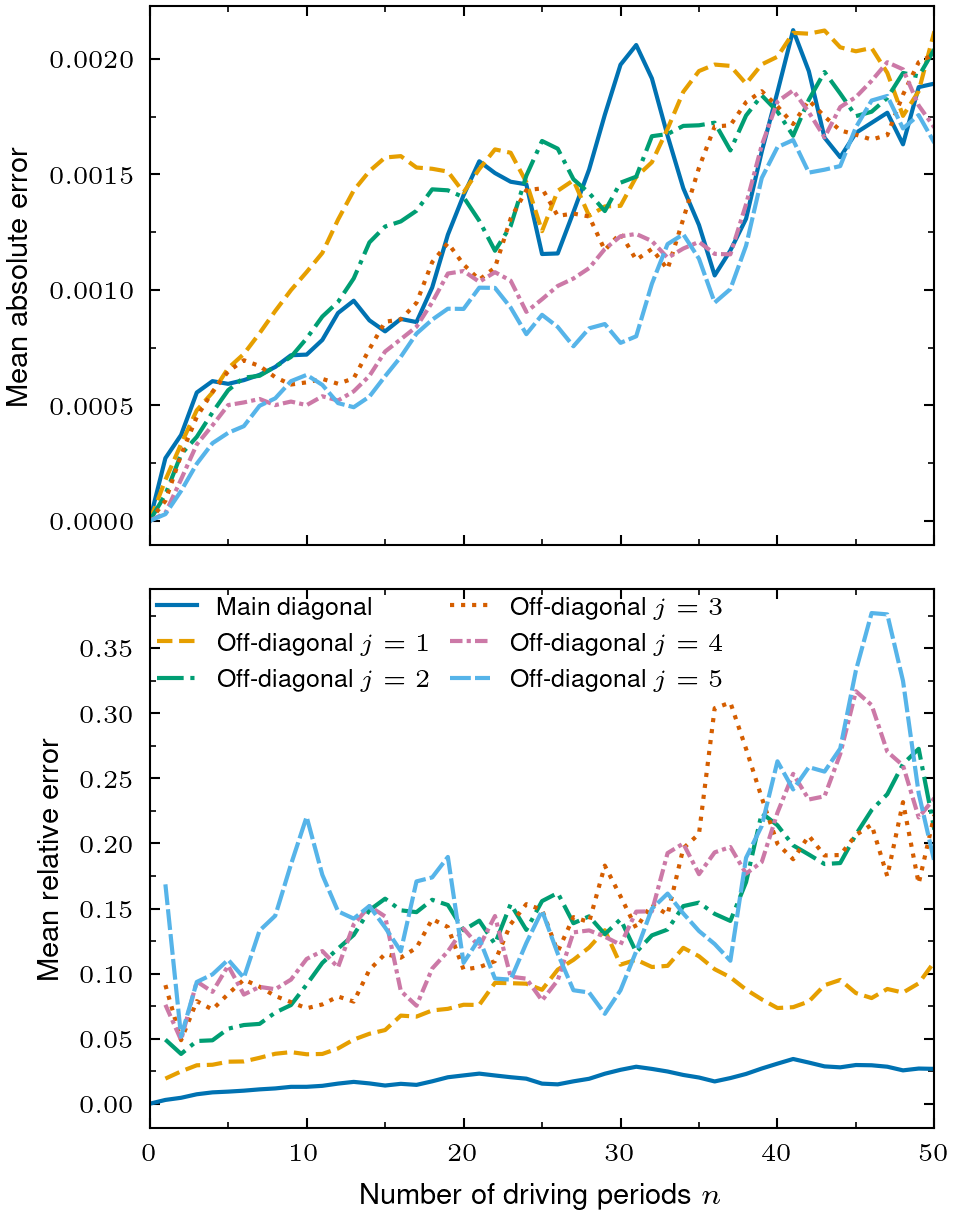

In [24]:
data = _load(f"diag_errors_iref{k}.npy")   # (6, 2, N)
Nj, _, Nn = data.shape
ns = np.arange(Nn)

fig, (ax_abs, ax_rel) = plt.subplots(
    2, 1,
    figsize=(PRL_COL, 2 * PRL_COL * 0.72),
    sharex=True,
)
fig.subplots_adjust(hspace=0.08)

for j in range(Nj):
    kw = dict(color=PALETTE[j], lw=1, ls=LINESTYLES[j], label=DIAG_LABELS[j])
    ax_abs.plot(ns, data[j, 0, :], **kw)
    ax_rel.plot(ns, data[j, 1, :], **kw)

for ax in (ax_abs, ax_rel):
    _ticks(ax)
    ax.set_xlim(ns[0], ns[-1])

ax_abs.set_ylabel(r"Mean absolute error")
ax_rel.set_ylabel(r"Mean relative error")
ax_rel.set_xlabel(r"Number of driving periods $n$")
ax_rel.legend(loc="upper left", frameon=False,
              ncol=2, handlelength=1.6, columnspacing=0.8,
              borderpad=0, borderaxespad=0.3)


_save(fig, f"plot1_diagonal_errors_iref{k}.pdf")
plt.show()

## Plot 2 — Hamiltonian diagonals: ideal vs AOD

Real and imaginary parts of the first `N_DIAG` diagonals of $H_\mathrm{fl}$, comparing ideal vs AOD, for each drive.

In [13]:
Hs = _load(f"ideal_vs_aod_zeroth_iref{k}.npy")   # (4, L, L) complex
print(Hs)
H_ideal =Hs["H_fl_ideal"]
H_sd= Hs["H_fl_sd"]
H_ideal_2d= Hs["H_fl_ideal_2d"]
H_2d =  Hs[" H_fl_2d"]
L    = H_ideal.shape[0]
site = np.arange(L)

NpzFile '../data\\ideal_vs_aod_zeroth_iref2.npy' with keys: H_fl_ideal, H_fl_sd, H_fl_ideal_2d,  H_fl_2d


Saved: plot2_hamiltonian_combined_iref2_prl.pdf


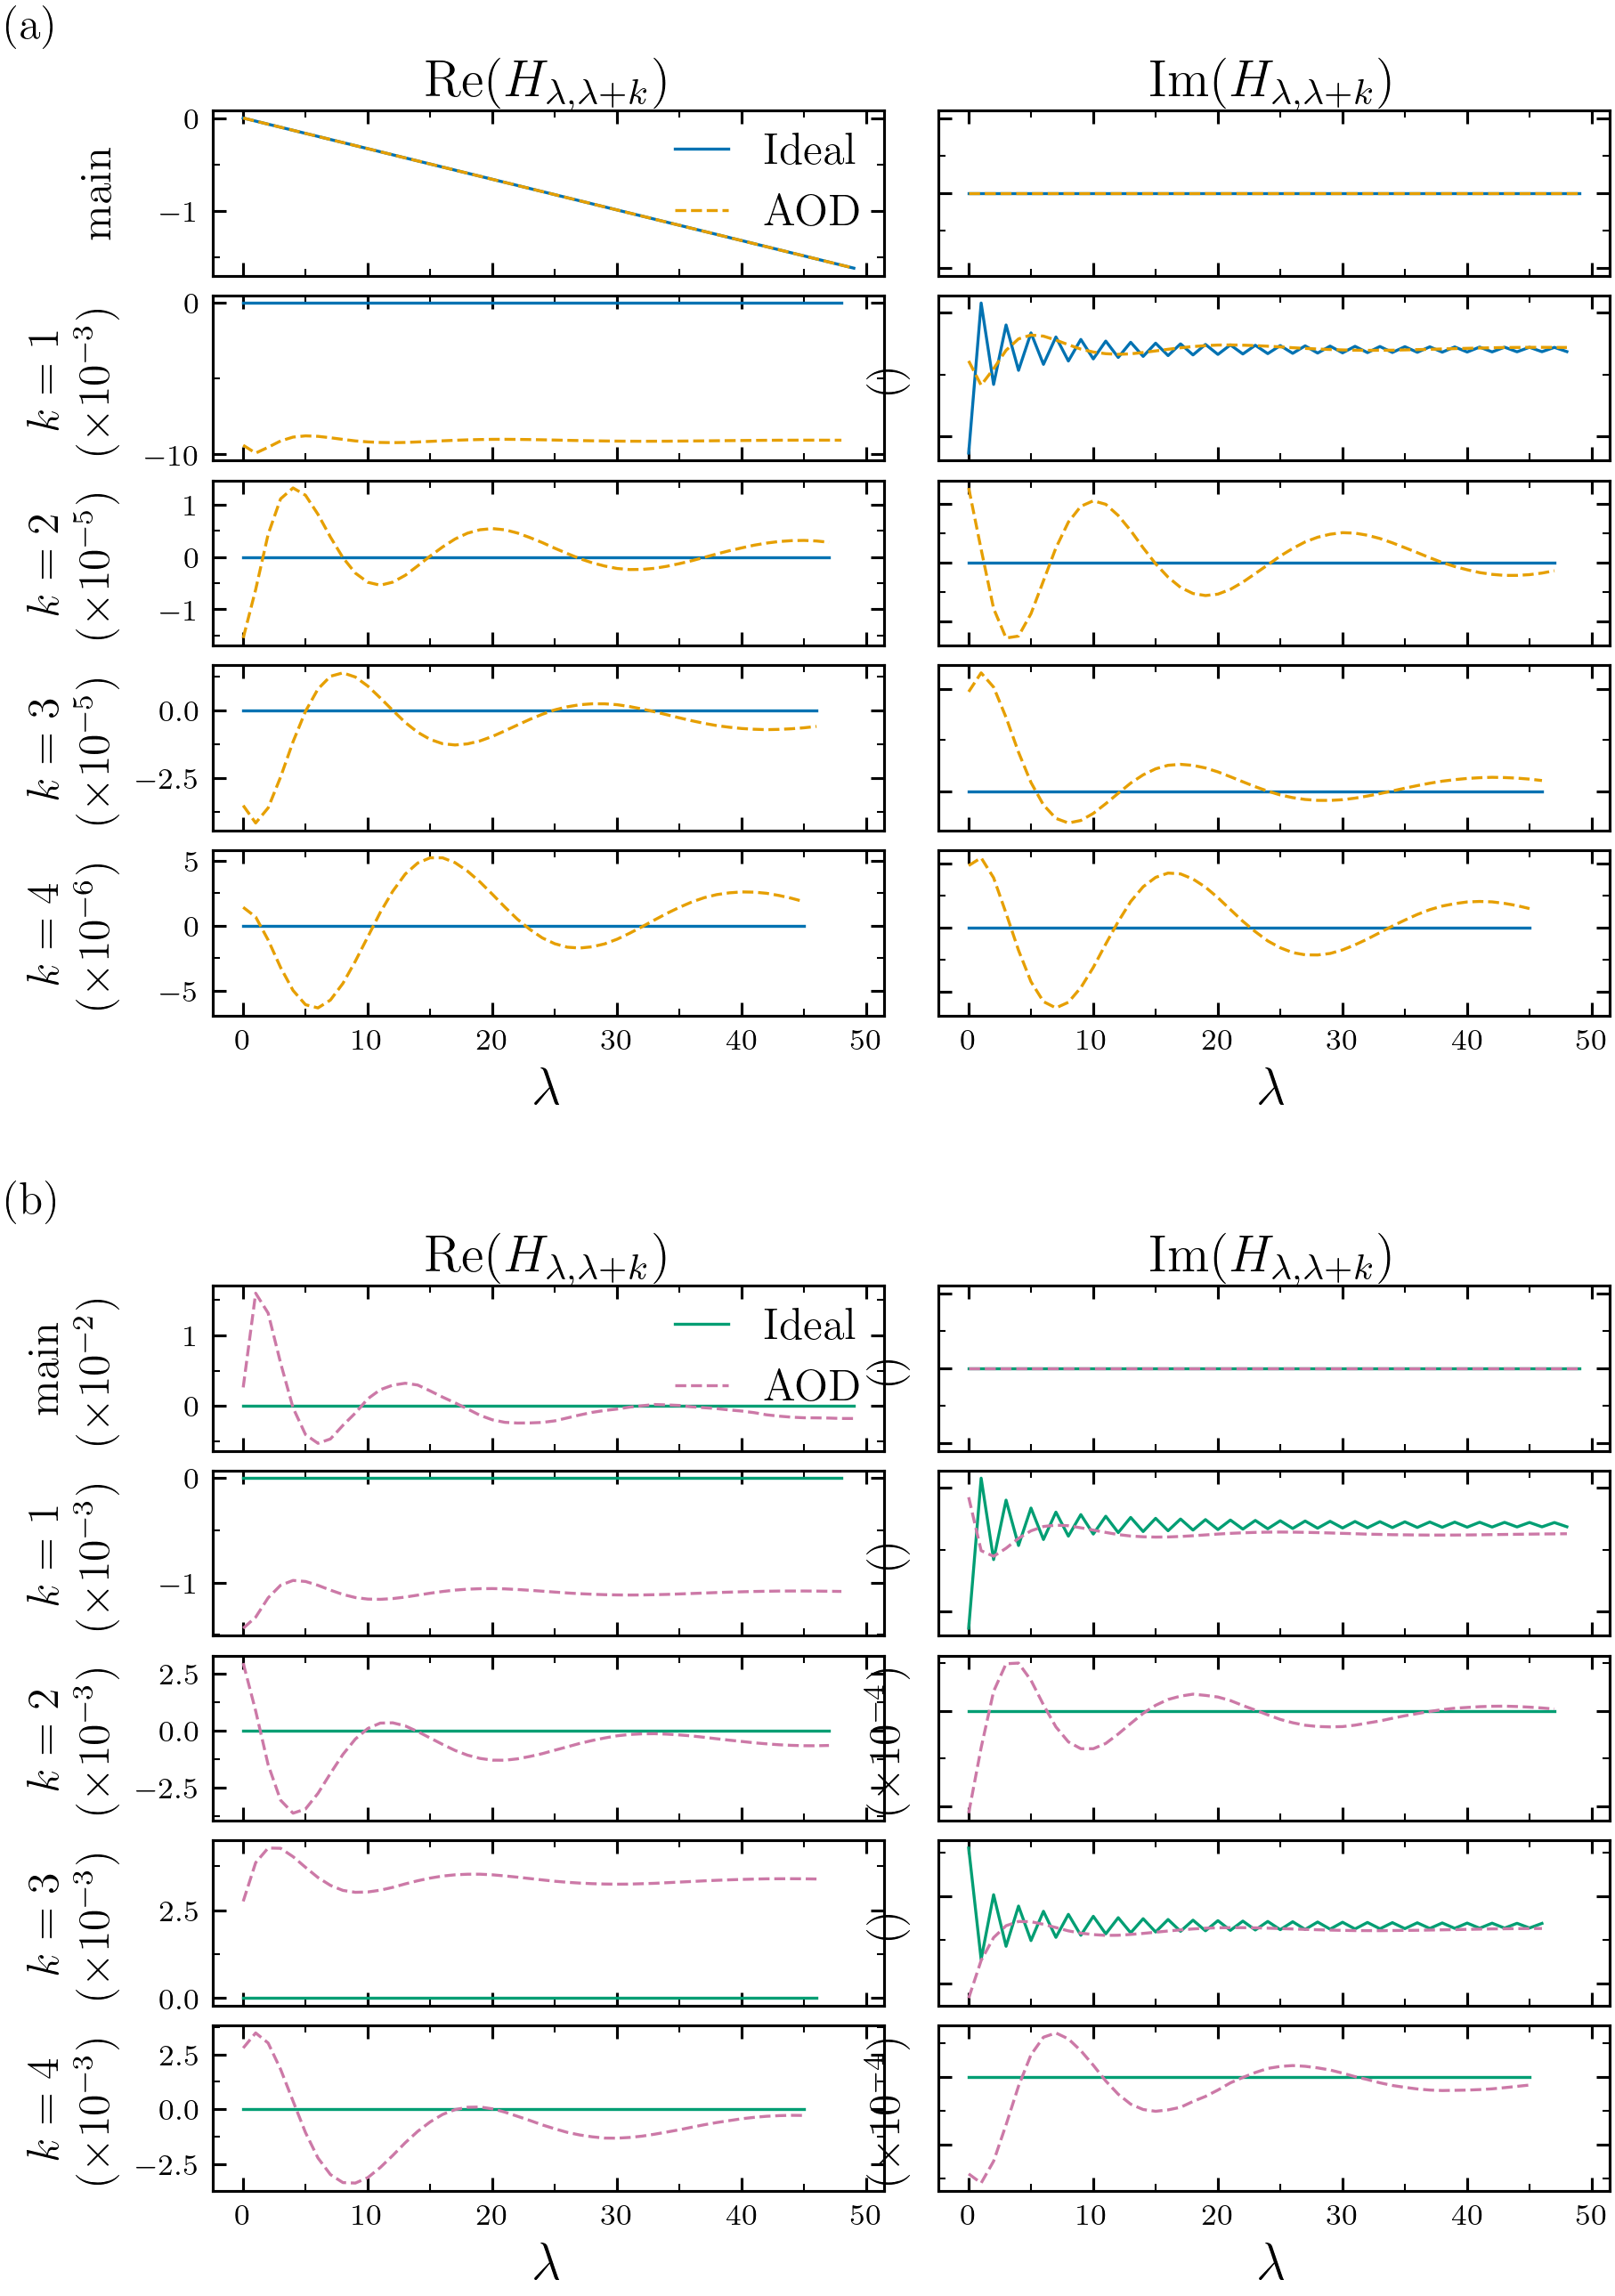

In [14]:
from matplotlib.ticker import FuncFormatter

def hamiltonian_figure(H_ref, H_aod, color_aod, drive_label,
                       outname=None, subfig=None, panel_label=None):
    if subfig is None:
        fig, axes = plt.subplots(
            N_DIAG, 2,
            figsize=(PRL_2COL, N_DIAG * 1.1),
            sharex=True, sharey=False,
        )
        own_fig = True
    else:
        fig = subfig
        axes = subfig.subplots(N_DIAG, 2, sharex=True)
        own_fig = False

    fig.subplots_adjust(hspace=0.12, wspace=0.08)

    for j in range(N_DIAG):
        d_ref = np.diag(H_ref, j)
        d_aod = np.diag(H_aod, j)
        xs    = site[: len(d_ref)]

        ax_re, ax_im = axes[j, 0], axes[j, 1]
        diag_str = r"main" if j == 0 else rf"$k={j}$"

        for ax, data_ref, data_aod in [
            (ax_re, d_ref.real, d_aod.real),
            (ax_im, d_ref.imag, d_aod.imag),
        ]:
            # scale per column independently
            col_vmax = max(np.abs(data_ref).max(), np.abs(data_aod).max())
            if col_vmax == 0:
                col_exp, col_scale = 0, 1
            else:
                col_exp   = int(np.floor(np.log10(col_vmax)))
                col_scale = 10**col_exp if abs(col_exp) >= 2 else 1
                col_exp   = col_exp     if abs(col_exp) >= 2 else 0

            ax.plot(xs, data_ref / col_scale, color=color_aod[0],
                    lw=0.8, ls="-",  label="Ideal")
            ax.plot(xs, data_aod / col_scale, color=color_aod[1],
                    lw=0.8, ls="--", label="AOD")
            ax.ticklabel_format(useOffset=False)
            _ticks(ax)

            col_scale_str = rf"$\times10^{{{col_exp}}}$" if col_exp != 0 else ""
            ax._scale_str = col_scale_str   # stash for ylabel below

        # left column ylabel: diag label + Re scale
        ax_re.set_ylabel(
            diag_str + ("\n" + f"({ax_re._scale_str})" if ax_re._scale_str else ""),
            fontsize=12,
        )
        # right column: suppress tick labels, but show Im scale if different
        ax_im.tick_params(labelleft=False)
        if ax_im._scale_str != ax_re._scale_str:
            ax_im.set_ylabel(f"({ax_im._scale_str})", fontsize=12)

    axes[-1, 0].set_xlabel(r"$\lambda$", fontsize=14)
    axes[-1, 1].set_xlabel(r"$\lambda$", fontsize=14)
    axes[0, 0].legend(loc="upper right", frameon=False,
                      handlelength=1.2, borderpad=0, fontsize=12)
    axes[0, 0].set_title(r"Re$(H_{\lambda,\lambda+k})$", pad=3, fontsize=14)
    axes[0, 1].set_title(r"Im$(H_{\lambda,\lambda+k})$", pad=3, fontsize=14)

    if panel_label is not None:
        fig.text(0.01, 0.97, panel_label, fontweight="bold",
                 va="top", ha="left", fontsize=12,
                 transform=fig.transSubfigure)

    fig.align_ylabels(axes[:, 0])

    if own_fig:
        if outname:
            _save(fig, outname)
        plt.show()

    return fig, axes


# ── combined figure ───────────────────────────────────────────────────────────
fig = plt.figure(figsize=(PRL_2COL, 2 * N_DIAG * 0.88))
subfigs = fig.subfigures(2, 1, hspace=0.)

hamiltonian_figure(H_ideal,    H_sd,  [PALETTE[0], PALETTE[1]], "1D",
                   subfig=subfigs[0], panel_label="(a)")
hamiltonian_figure(H_ideal_2d, H_2d,  [PALETTE[2], PALETTE[4]], "2D",
                   subfig=subfigs[1], panel_label="(b)")

_save(fig, f"plot2_hamiltonian_combined_iref{k}_prl.pdf")
plt.show()

Saved: plot2_hamiltonian_combined_iref2_prl.pdf


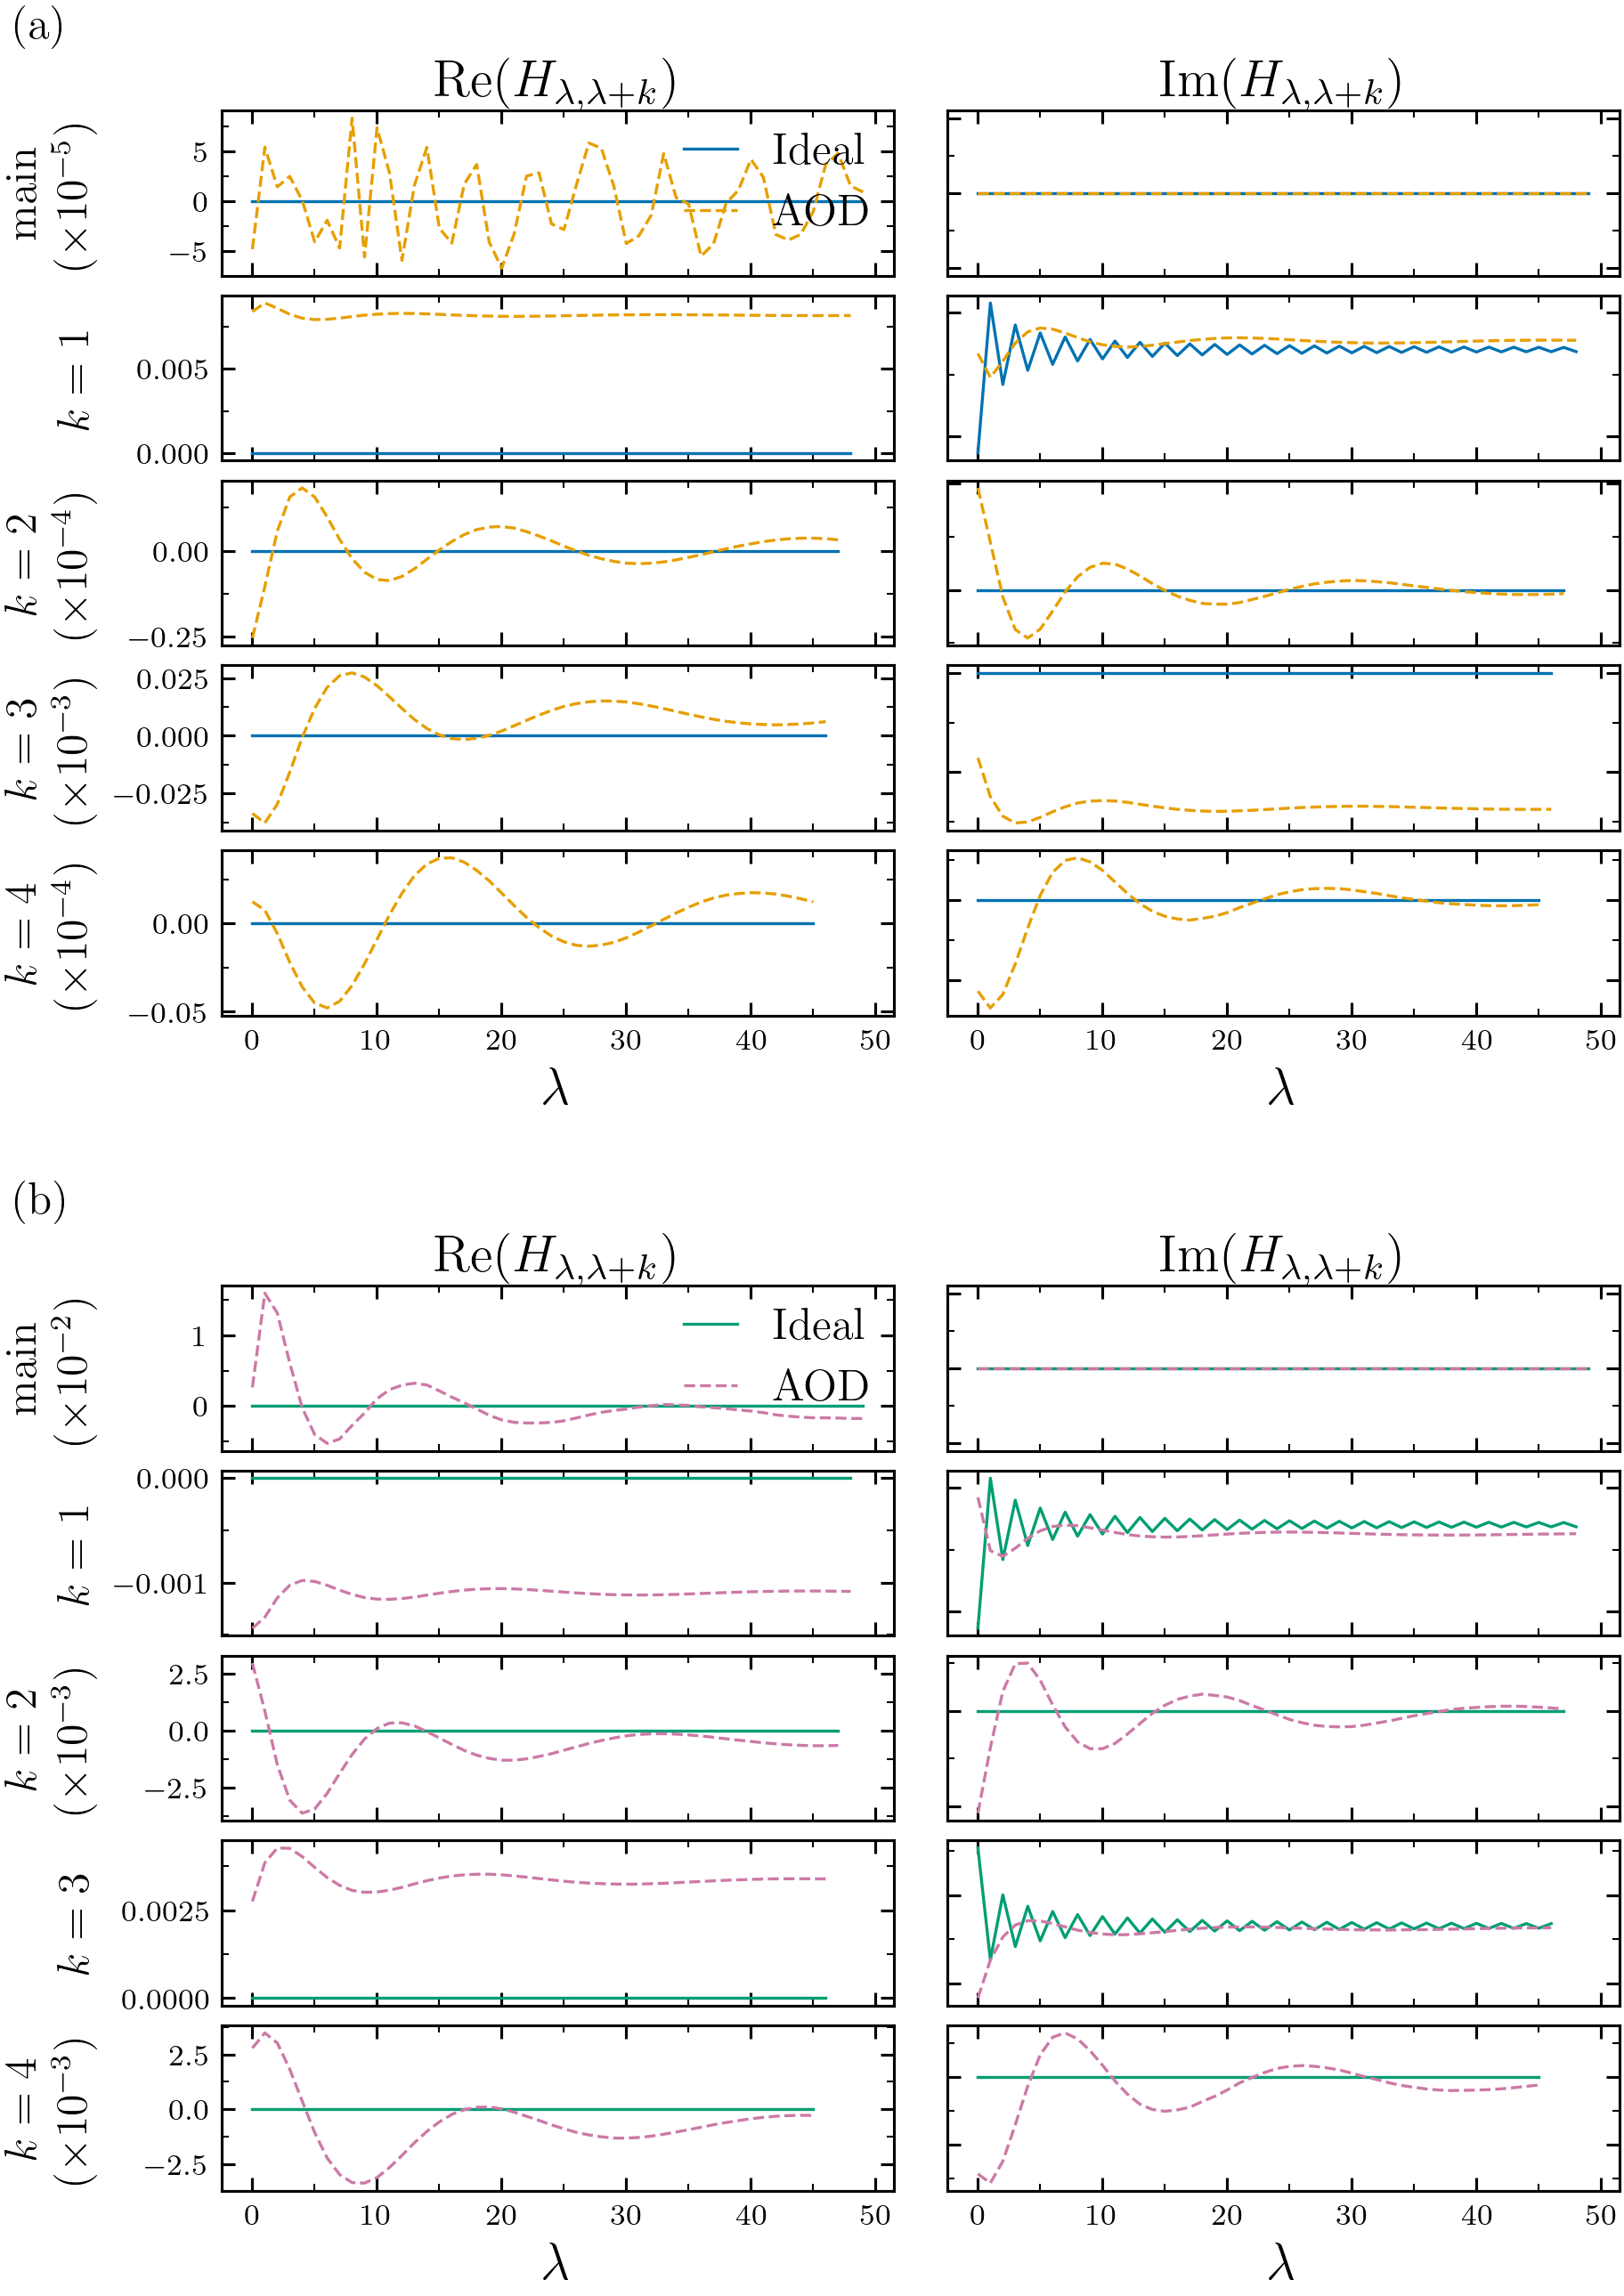

In [9]:


mpl.rcParams.update({
    "font.size":       16,
    "axes.titlesize": 10,
    "axes.labelsize":  10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

def hamiltonian_figure(H_ref, H_aod, color_aod, drive_label,
                       outname=None, subfig=None, panel_label=None):
    if subfig is None:
        fig, axes = plt.subplots(
            N_DIAG, 2,
            figsize=(PRL_2COL, N_DIAG * 1.1),
            sharex=True, sharey=False,
        )
        own_fig = True
    else:
        fig = subfig
        axes = subfig.subplots(N_DIAG, 2, sharex=True)
        own_fig = False

    fig.subplots_adjust(hspace=0.12, wspace=0.08)

    for j in range(N_DIAG):
        d_ref = np.diag(H_ref, j)
        d_aod = np.diag(H_aod, j)
        xs    = site[: len(d_ref)]

        ax_re, ax_im = axes[j, 0], axes[j, 1]

        vmax = max(
            np.abs(d_ref.real).max(), np.abs(d_aod.real).max(),
            np.abs(d_ref.imag).max(), np.abs(d_aod.imag).max(),
        )
        if vmax == 0:
            scale, exp = 1, 0
        else:
            exp   = int(np.floor(np.log10(vmax)))
            scale = 10**exp if abs(exp) >= 2 else 1
            exp   = exp     if abs(exp) >= 2 else 0

        for ax, data_ref, data_aod in [
            (ax_re, d_ref.real, d_aod.real),
            (ax_im, d_ref.imag, d_aod.imag),
        ]:
            ax.plot(xs, data_ref / scale, color=color_aod[0], lw=0.8, ls="-",  label="Ideal")
            ax.plot(xs, data_aod / scale, color=color_aod[1], lw=0.8, ls="--", label="AOD")
            ax.ticklabel_format(useOffset=False)
            _ticks(ax)

        diag_str  = r"main" if j == 0 else rf"$k={j}$"
        scale_str = rf"$\times10^{{{exp}}}$" if exp != 0 else ""
        ax_re.set_ylabel(diag_str + ("\n" + f"({scale_str})" if scale_str else ""), fontsize = 12,)
        ax_im.tick_params(labelleft=False)

    axes[-1, 0].set_xlabel(r"$\lambda$", fontsize = 14,)
    axes[-1, 1].set_xlabel(r"$\lambda$", fontsize = 14,)
    axes[0, 0].legend(loc="upper right", frameon=False, handlelength=1.2, borderpad=0, fontsize = 12,)
    axes[0, 0].set_title(r"Re$(H_{\lambda,\lambda+k})$", pad=3, fontsize = 14,)
    axes[0, 1].set_title(r"Im$(H_{\lambda,\lambda+k})$", pad=3, fontsize = 14,)

    if panel_label is not None:
        fig.text(0.01, 0.97, panel_label, fontweight="bold",
                 va="top", ha="left", fontsize = 12, transform=fig.transSubfigure)

    fig.align_ylabels(axes[:, 0])

    if own_fig:
        if outname:
            _save(fig, outname)
        plt.show()

    return fig, axes


# ── combined figure ───────────────────────────────────────────────────────────
fig = plt.figure(figsize=(PRL_2COL, 2 * N_DIAG * 0.88))
subfigs = fig.subfigures(2, 1, hspace=0.)

hamiltonian_figure(H_ideal,    H_sd,  [PALETTE[0], PALETTE[1]], "1D",
                   subfig=subfigs[0], panel_label="(a)")
hamiltonian_figure(H_ideal_2d, H_2d,  [PALETTE[2], PALETTE[4]], "2D",
                   subfig=subfigs[1], panel_label="(b)")

_save(fig, f"plot2_hamiltonian_combined_iref{k}_prl.pdf")
plt.show()

Saved: plot2_hamiltonian_combined_iref2_NP.pdf


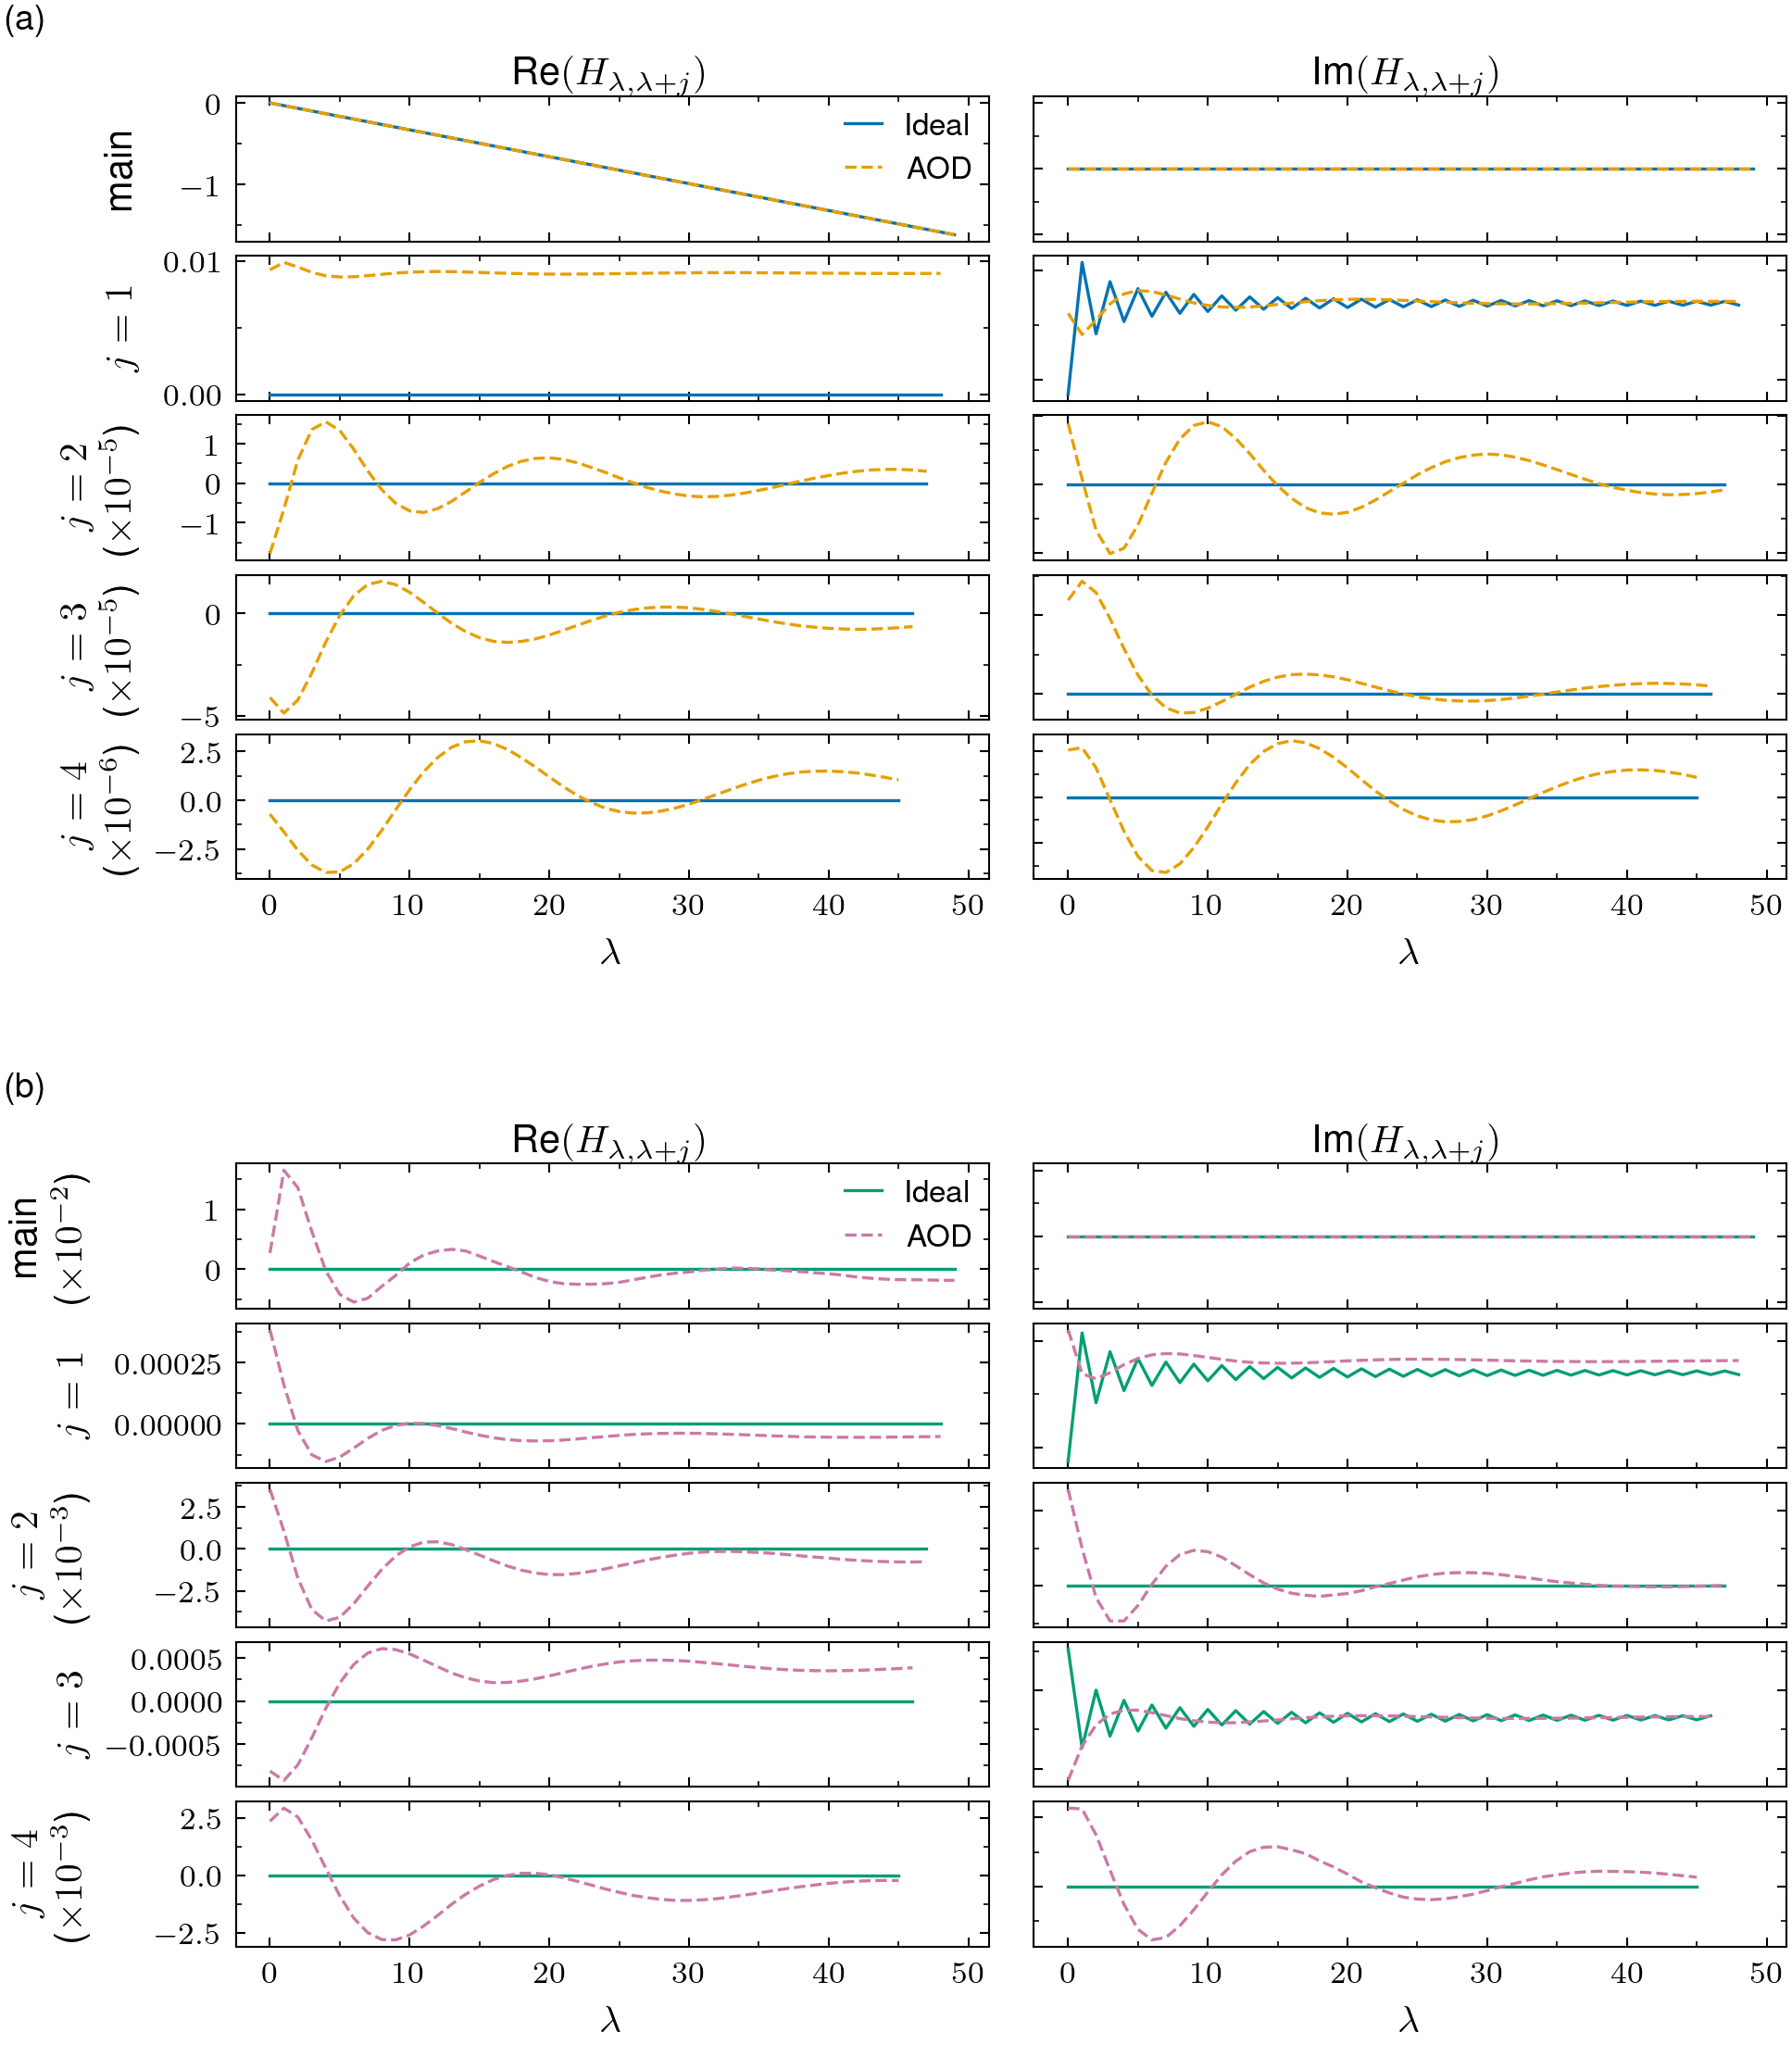

In [ ]:
mpl.rcParams.update(NP_RC)
def hamiltonian_figure_np(H_ref, H_aod, color_aod, outname=None,
                           subfig=None, panel_label=None):
    """
    Nature Physics single-column layout.
    Two columns (Re / Im) share one y-axis label per row.
    All fontsizes from rcParams — no hardcoded values.
    """
    if subfig is None:
        fig, axes = plt.subplots(
            N_DIAG, 2,
            figsize=(NP_2COL, N_DIAG * 0.75),
            sharex=True,
        )
        own_fig = True
    else:
        fig = subfig
        axes = subfig.subplots(N_DIAG, 2, sharex=True)
        own_fig = False

    fig.subplots_adjust(hspace=0.10, wspace=0.06)

    for j in range(N_DIAG):
        d_ref = np.diag(H_ref, j)
        d_aod = np.diag(H_aod, j)
        xs    = site[: len(d_ref)]

        ax_re, ax_im = axes[j, 0], axes[j, 1]

        # shared scale across Re and Im for this diagonal
        vmax = max(
            np.abs(d_ref.real).max(), np.abs(d_aod.real).max(),
            np.abs(d_ref.imag).max(), np.abs(d_aod.imag).max(),
        )
        if vmax == 0:
            scale, exp = 1, 0
        else:
            exp   = int(np.floor(np.log10(vmax)))
            scale = 10**exp if abs(exp) >= 2 else 1
            exp   = exp     if abs(exp) >= 2 else 0

        for ax, data_ref, data_aod in [
            (ax_re, d_ref.real, d_aod.real),
            (ax_im, d_ref.imag, d_aod.imag),
        ]:
            ax.plot(xs, data_ref / scale, color=color_aod[0], lw=0.8,
                    ls="-",  label="Ideal")
            ax.plot(xs, data_aod / scale, color=color_aod[1], lw=0.8,
                    ls="--", label="AOD")
            ax.ticklabel_format(useOffset=False)
            _ticks(ax)

        # single y-label on left column only
        diag_str  = "main" if j == 0 else rf"$j={j}$"
        scale_str = rf"$\times10^{{{exp}}}$" if exp != 0 else ""
        ax_re.set_ylabel(diag_str + ("\n" + f"({scale_str})" if scale_str else ""))

        # suppress right-column tick labels (they share the same scale)
        ax_im.tick_params(labelleft=False)

    axes[-1, 0].set_xlabel(r"$\lambda$")
    axes[-1, 1].set_xlabel(r"$\lambda$")

    axes[0, 0].legend(loc="upper right", frameon=False,
                      handlelength=1.2, borderpad=0)
    axes[0, 0].set_title(r"Re$(H_{\lambda,\lambda+j})$", pad=3)
    axes[0, 1].set_title(r"Im$(H_{\lambda,\lambda+j})$", pad=3)

    if panel_label is not None:
        fig.text(0.01, 0.97, panel_label, fontweight="bold",
                 va="top", ha="left", transform=fig.transSubfigure)

    fig.align_ylabels(axes[:, 0])

    if own_fig:
        if outname:
            _save(fig, outname)
        plt.show()
    return fig, axes


# ── combined figure: (a) single-drive, (b) two-drive ─────────────────────────
fig = plt.figure(figsize=(NP_2COL, 2 * N_DIAG * 0.75))
subfigs = fig.subfigures(2, 1, hspace=0.05)

hamiltonian_figure_np(H_ideal,    H_sd, [PALETTE[0], PALETTE[1]],
                      subfig=subfigs[0], panel_label="(a)")
hamiltonian_figure_np(H_ideal_2d, H_2d, [PALETTE[2], PALETTE[4]],
                      subfig=subfigs[1], panel_label="(b)")

_save(fig, f"plot2_hamiltonian_combined_iref{k}_NP.pdf")
plt.show()

In [ ]:
Hs = _load(f"ideal_vs_aod_zeroth_iref{k}.npy")   # (4, L, L) complex
print(Hs)
H_ideal =Hs["H_fl_ideal"]
H_sd= Hs["H_fl_sd"]
H_ideal_2d= Hs["H_fl_ideal_2d"]
H_2d =  Hs[" H_fl_2d"]
L    = H_ideal.shape[0]
site = np.arange(L)

def hamiltonian_figure(H_ref, H_aod, color_aod, drive_label, outname):
    fig, axes = plt.subplots(
        N_DIAG, 2,
        figsize=(PRL_2COL, N_DIAG * 0.88),
        sharex=True,
    )
    fig.subplots_adjust(hspace=0.12, wspace=0.38)

    for j in range(N_DIAG):
        d_ref = np.diag(H_ref, j)
        d_aod = np.diag(H_aod, j)
        xs    = site[: len(d_ref)]

        ax_re, ax_im = axes[j, 0], axes[j, 1]

        # determine a clean scale factor from the larger of the two curves
        for ax, data_ref, data_aod in [
            (ax_re, d_ref.real, d_aod.real),
            (ax_im, d_ref.imag, d_aod.imag),
        ]:
            vmax = max(np.abs(data_ref).max(), np.abs(data_aod).max())
            if vmax == 0:
                scale, exp = 1, 0
            else:
                exp   = int(np.floor(np.log10(vmax)))
                # only scale if the exponent warrants it
                if abs(exp) >= 2:
                    scale = 10 ** exp
                else:
                    scale, exp = 1, 0

            ax.plot(xs, data_ref / scale, color=color_aod[0], lw=0.8, ls="-",  label="Ideal")
            ax.plot(xs, data_aod / scale, color=color_aod[1],  lw=0.8, ls="--", label="AOD")

            diag_str = r"main" if j == 0 else rf"$j={j}$"
            part_str = r"Re" if ax is ax_re else r"Im"
            if exp != 0:
                scale_str = rf"$\times10^{{{exp}}}$"
            else:
                scale_str = ""
            ax.set_ylabel(
                f" {diag_str} "
                + (f"\n ({scale_str})" if scale_str else ""),
                fontsize=7,
            )
            # suppress matplotlib's own offset entirely
            ax.ticklabel_format(useOffset=False)
            _ticks(ax)
            
    axes[-1, 0].set_xlabel(r"$\lambda$")
    axes[-1, 1].set_xlabel(r"$\lambda$")
    axes[0, 0].legend(loc="upper right", frameon=False, fontsize=7,
                      handlelength=1.2, borderpad=0)
    axes[0, 0].set_title(r"Re$(H_{\lambda,\lambda+j})$",      fontsize=12, pad=3)
    axes[0, 1].set_title(r"Imag$(H_{\lambda,\lambda+j})$", fontsize=12, pad=3)

    fig.align_ylabels(axes[:, 0])
    fig.align_ylabels(axes[:, 1])
    _save(fig, outname)
    plt.show()
    return fig

NpzFile '../data\\ideal_vs_aod_zeroth_iref2.npy' with keys:  H_fl_2d, H_fl_ideal, H_fl_sd, H_fl_ideal_2d


Saved: plot2_hamiltonian_sd_iref2.pdf


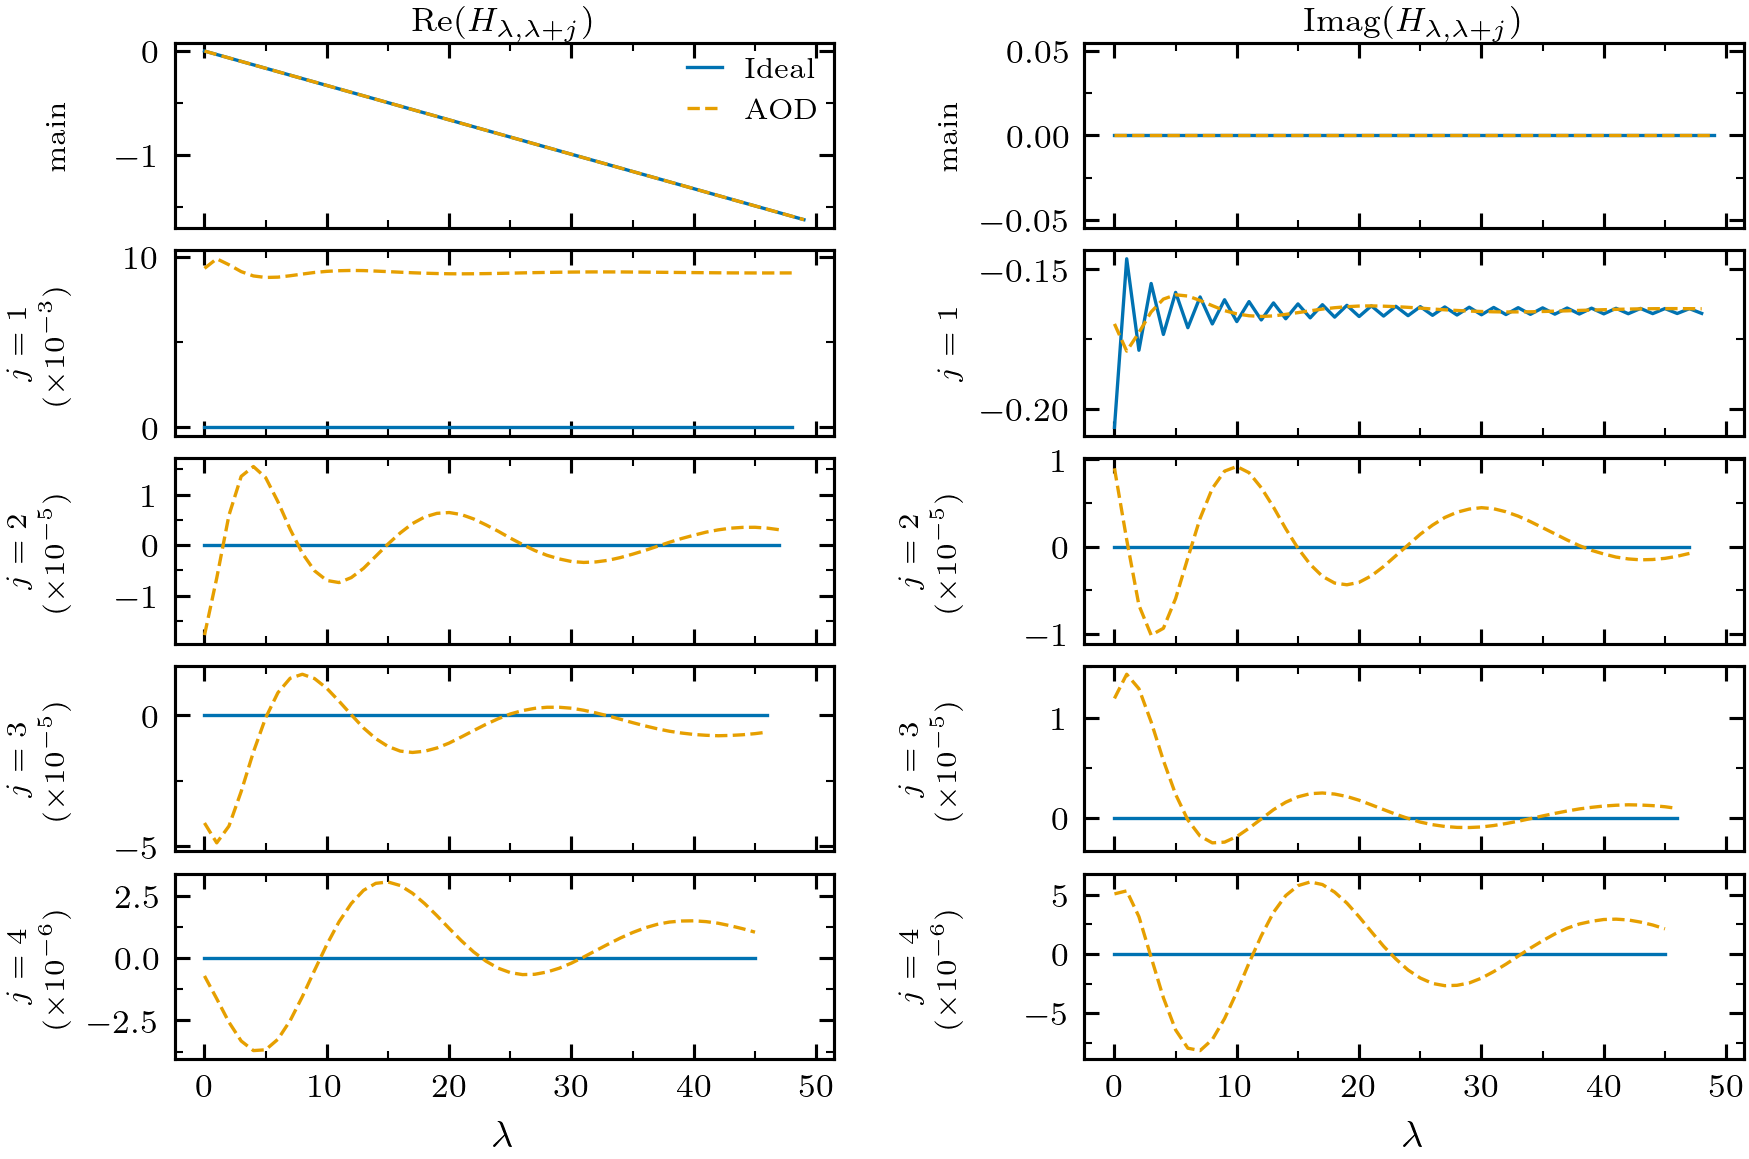

In [37]:

# Single drive
_ = hamiltonian_figure(H_ideal, H_sd, (PALETTE[0],PALETTE[1]),
                       "single drive", f"plot2_hamiltonian_sd_iref{k}.pdf")

Saved: plot2_hamiltonian_2d_iref2.pdf


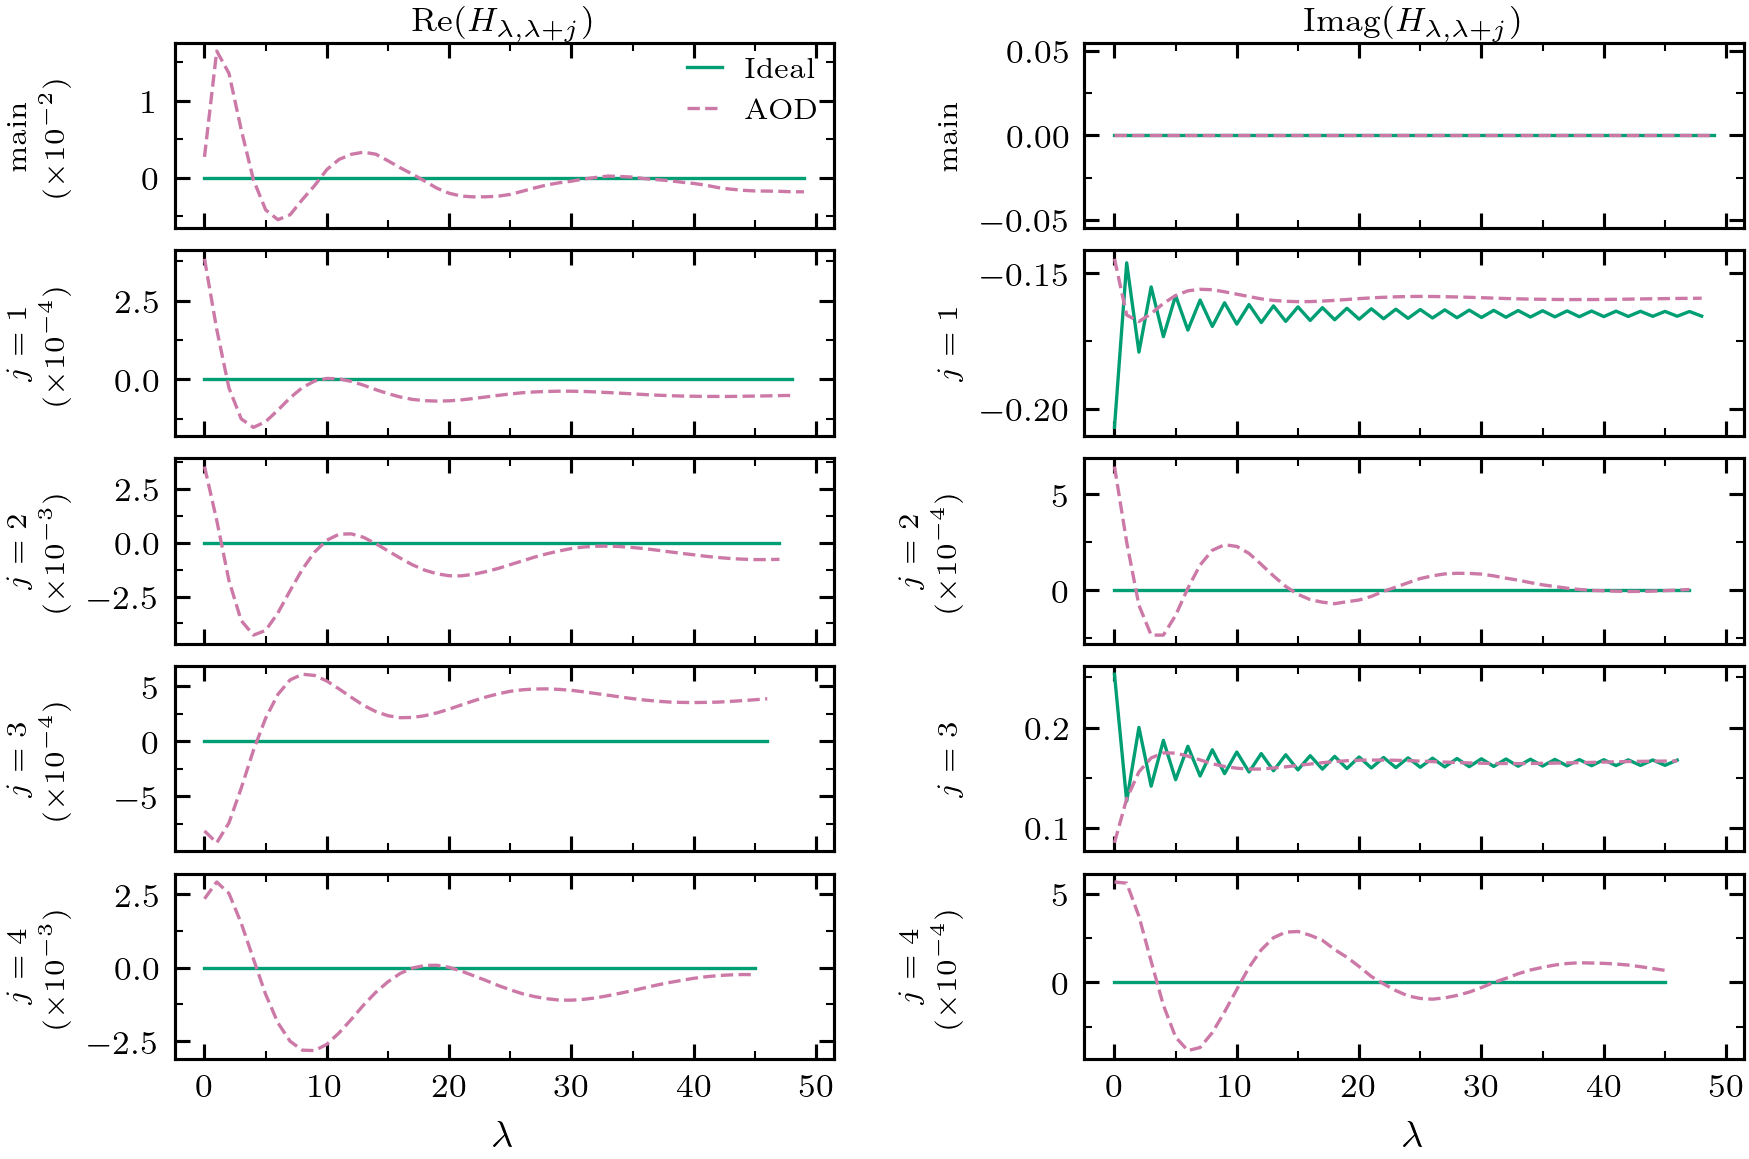

In [38]:
# Two drives
_ = hamiltonian_figure(H_ideal_2d, H_2d, (PALETTE[2],PALETTE[4]),
                       "two drives", f"plot2_hamiltonian_2d_iref{k}.pdf")

## Plot 3 — Unitary similarity: ideal RWA vs full numerical

Left: sorted eigenphase difference $\Delta\varphi$ vs mode index.  
Right: Floquet-mode overlap $|\langle v^\mathrm{ideal}_i | v^\mathrm{num}_j \rangle|^2$ as a heatmap.

Saved: plot3_unitary_matrix_elements_iref2.pdf


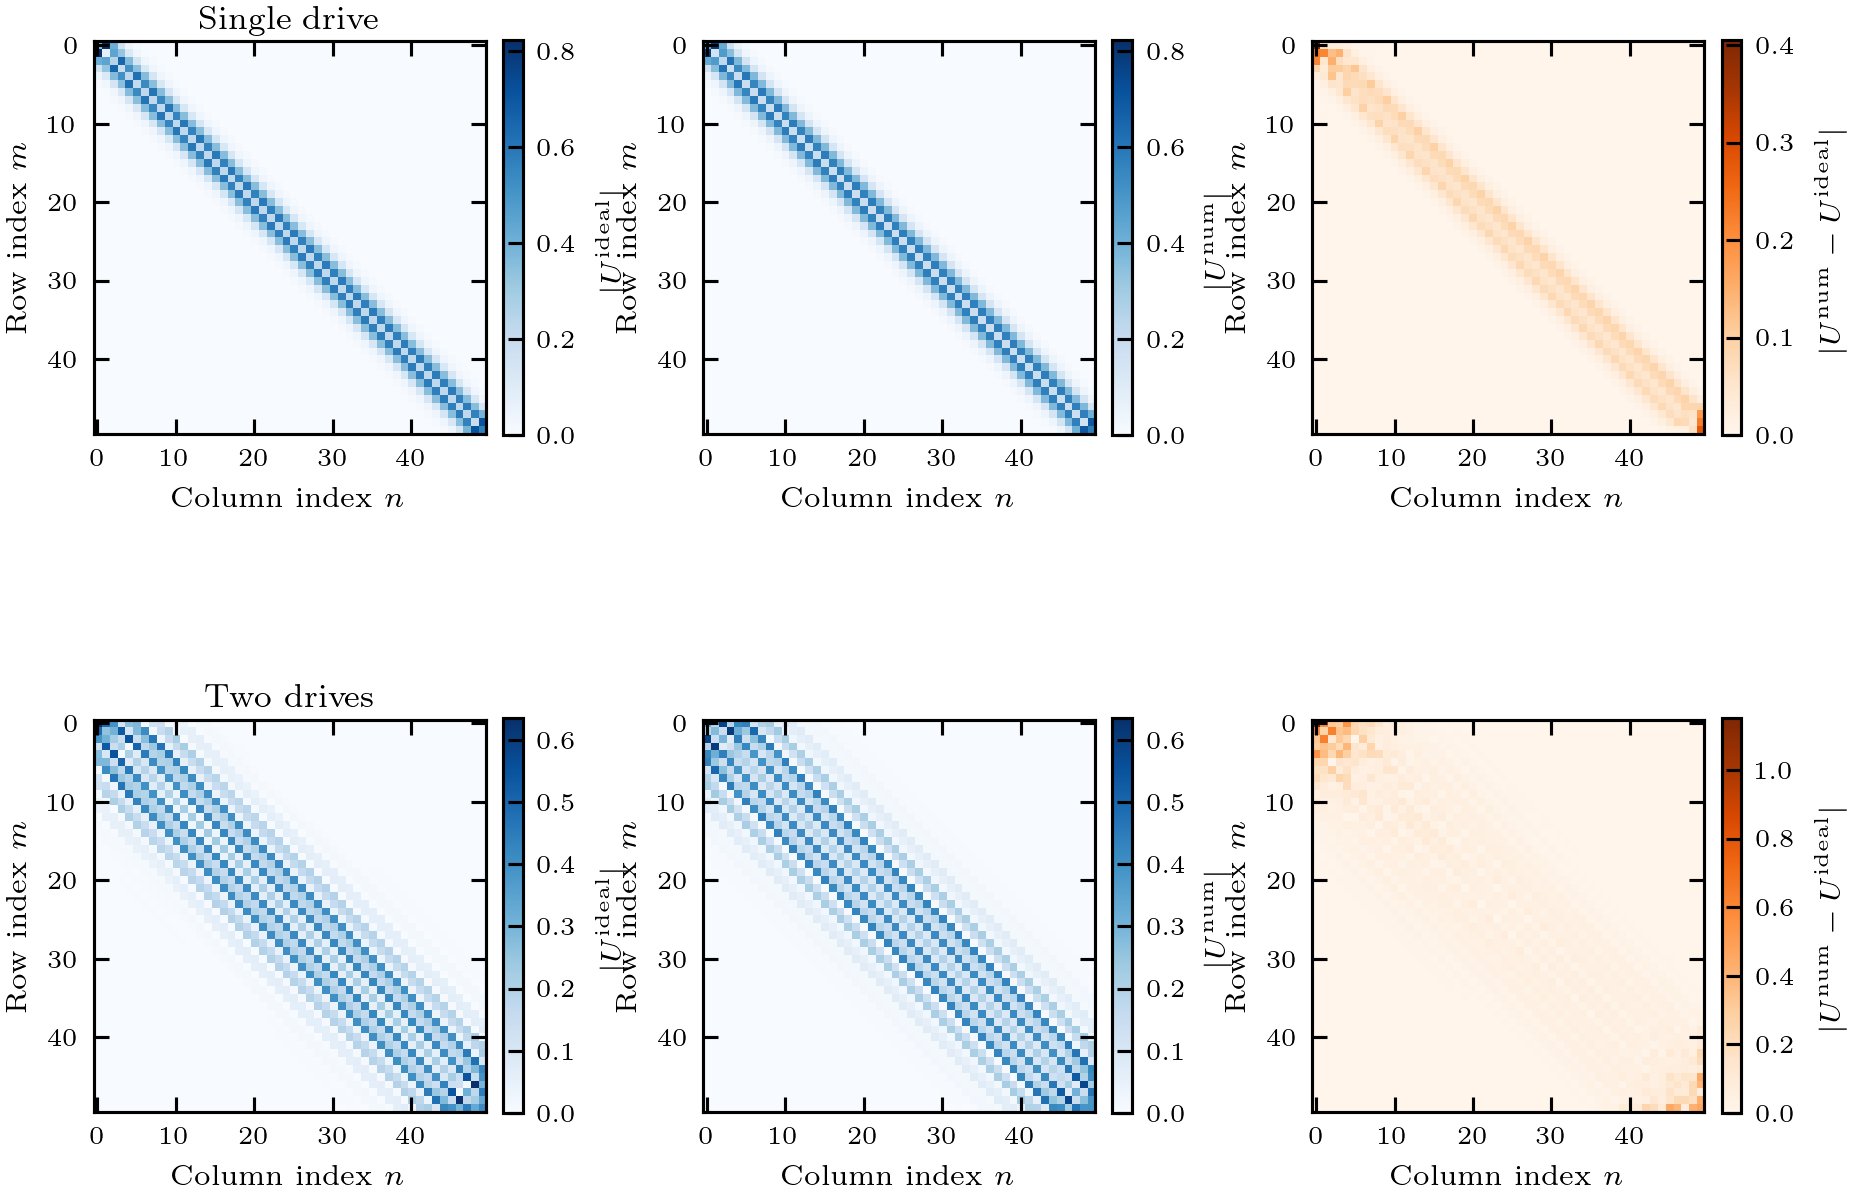

In [ ]:
Us = _load(f"ideal_vs_ideal_full_iref{k}.npy")   # (4, L, L) complex
U_ideal, U_fl, U_ideal_2d, U_fl_2d = Us["U_fl_ideal"], Us["U_fl"], Us["U_fl_ideal_2d"], Us[" U_fl_2d"]
rows = [
    (U_ideal,    U_fl,     "Single drive"),
    (U_ideal_2d, U_fl_2d,  "Two drives"),
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(PRL_2COL * 1.05, PRL_2COL * 0.75),
)
fig.subplots_adjust(hspace=0.38, wspace=0.42)

panel_labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]

for row_idx, (U_ref, U_num, drive_label) in enumerate(rows):
    abs_ref  = np.abs(U_ref)
    abs_num  = np.abs(U_num)
    abs_diff = np.abs(U_num - U_ref) /np.abs(U_ref).max()

    vmax_U    = max(abs_ref.max(), abs_num.max())
    vmax_diff = abs_diff.max()

    panels = [
        (axes[row_idx, 0], abs_ref,  "Blues",   0, vmax_U,
         r"$|U^{\mathrm{ideal}}|$"),
        (axes[row_idx, 1], abs_num,  "Blues",   0, vmax_U,
         r"$|U^{\mathrm{num}}|$"),
        (axes[row_idx, 2], abs_diff, "Oranges", 0, vmax_diff,
         r"$|U^{\mathrm{num}} - U^{\mathrm{ideal}}|$"),
    ]

    for col_idx, (ax, data, cmap, vmin, vmax, cblabel) in enumerate(panels):
        im = ax.imshow(data, origin="upper", aspect="equal",
                       cmap=cmap, vmin=vmin, vmax=vmax,
                       interpolation="none", rasterized=True)
        ax.set_xlabel(r"Column index $n$", fontsize=7)
        ax.set_ylabel(r"Row index $m$",    fontsize=7)
        ax.tick_params(labelsize=6)

        cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cb.set_label(cblabel, fontsize=7)
        cb.ax.tick_params(labelsize=6)

        if col_idx == 0:
            ax.set_title(drive_label, fontsize=8, pad=3)

        #_panel_label(ax, panel_labels[row_idx * 3 + col_idx], x=0.04, y=0.96)


_save(fig, f"plot3_unitary_matrix_elements_iref{k}.pdf")
plt.show()

Saved: plot4_diagonal_snapshots_iref2.pdf


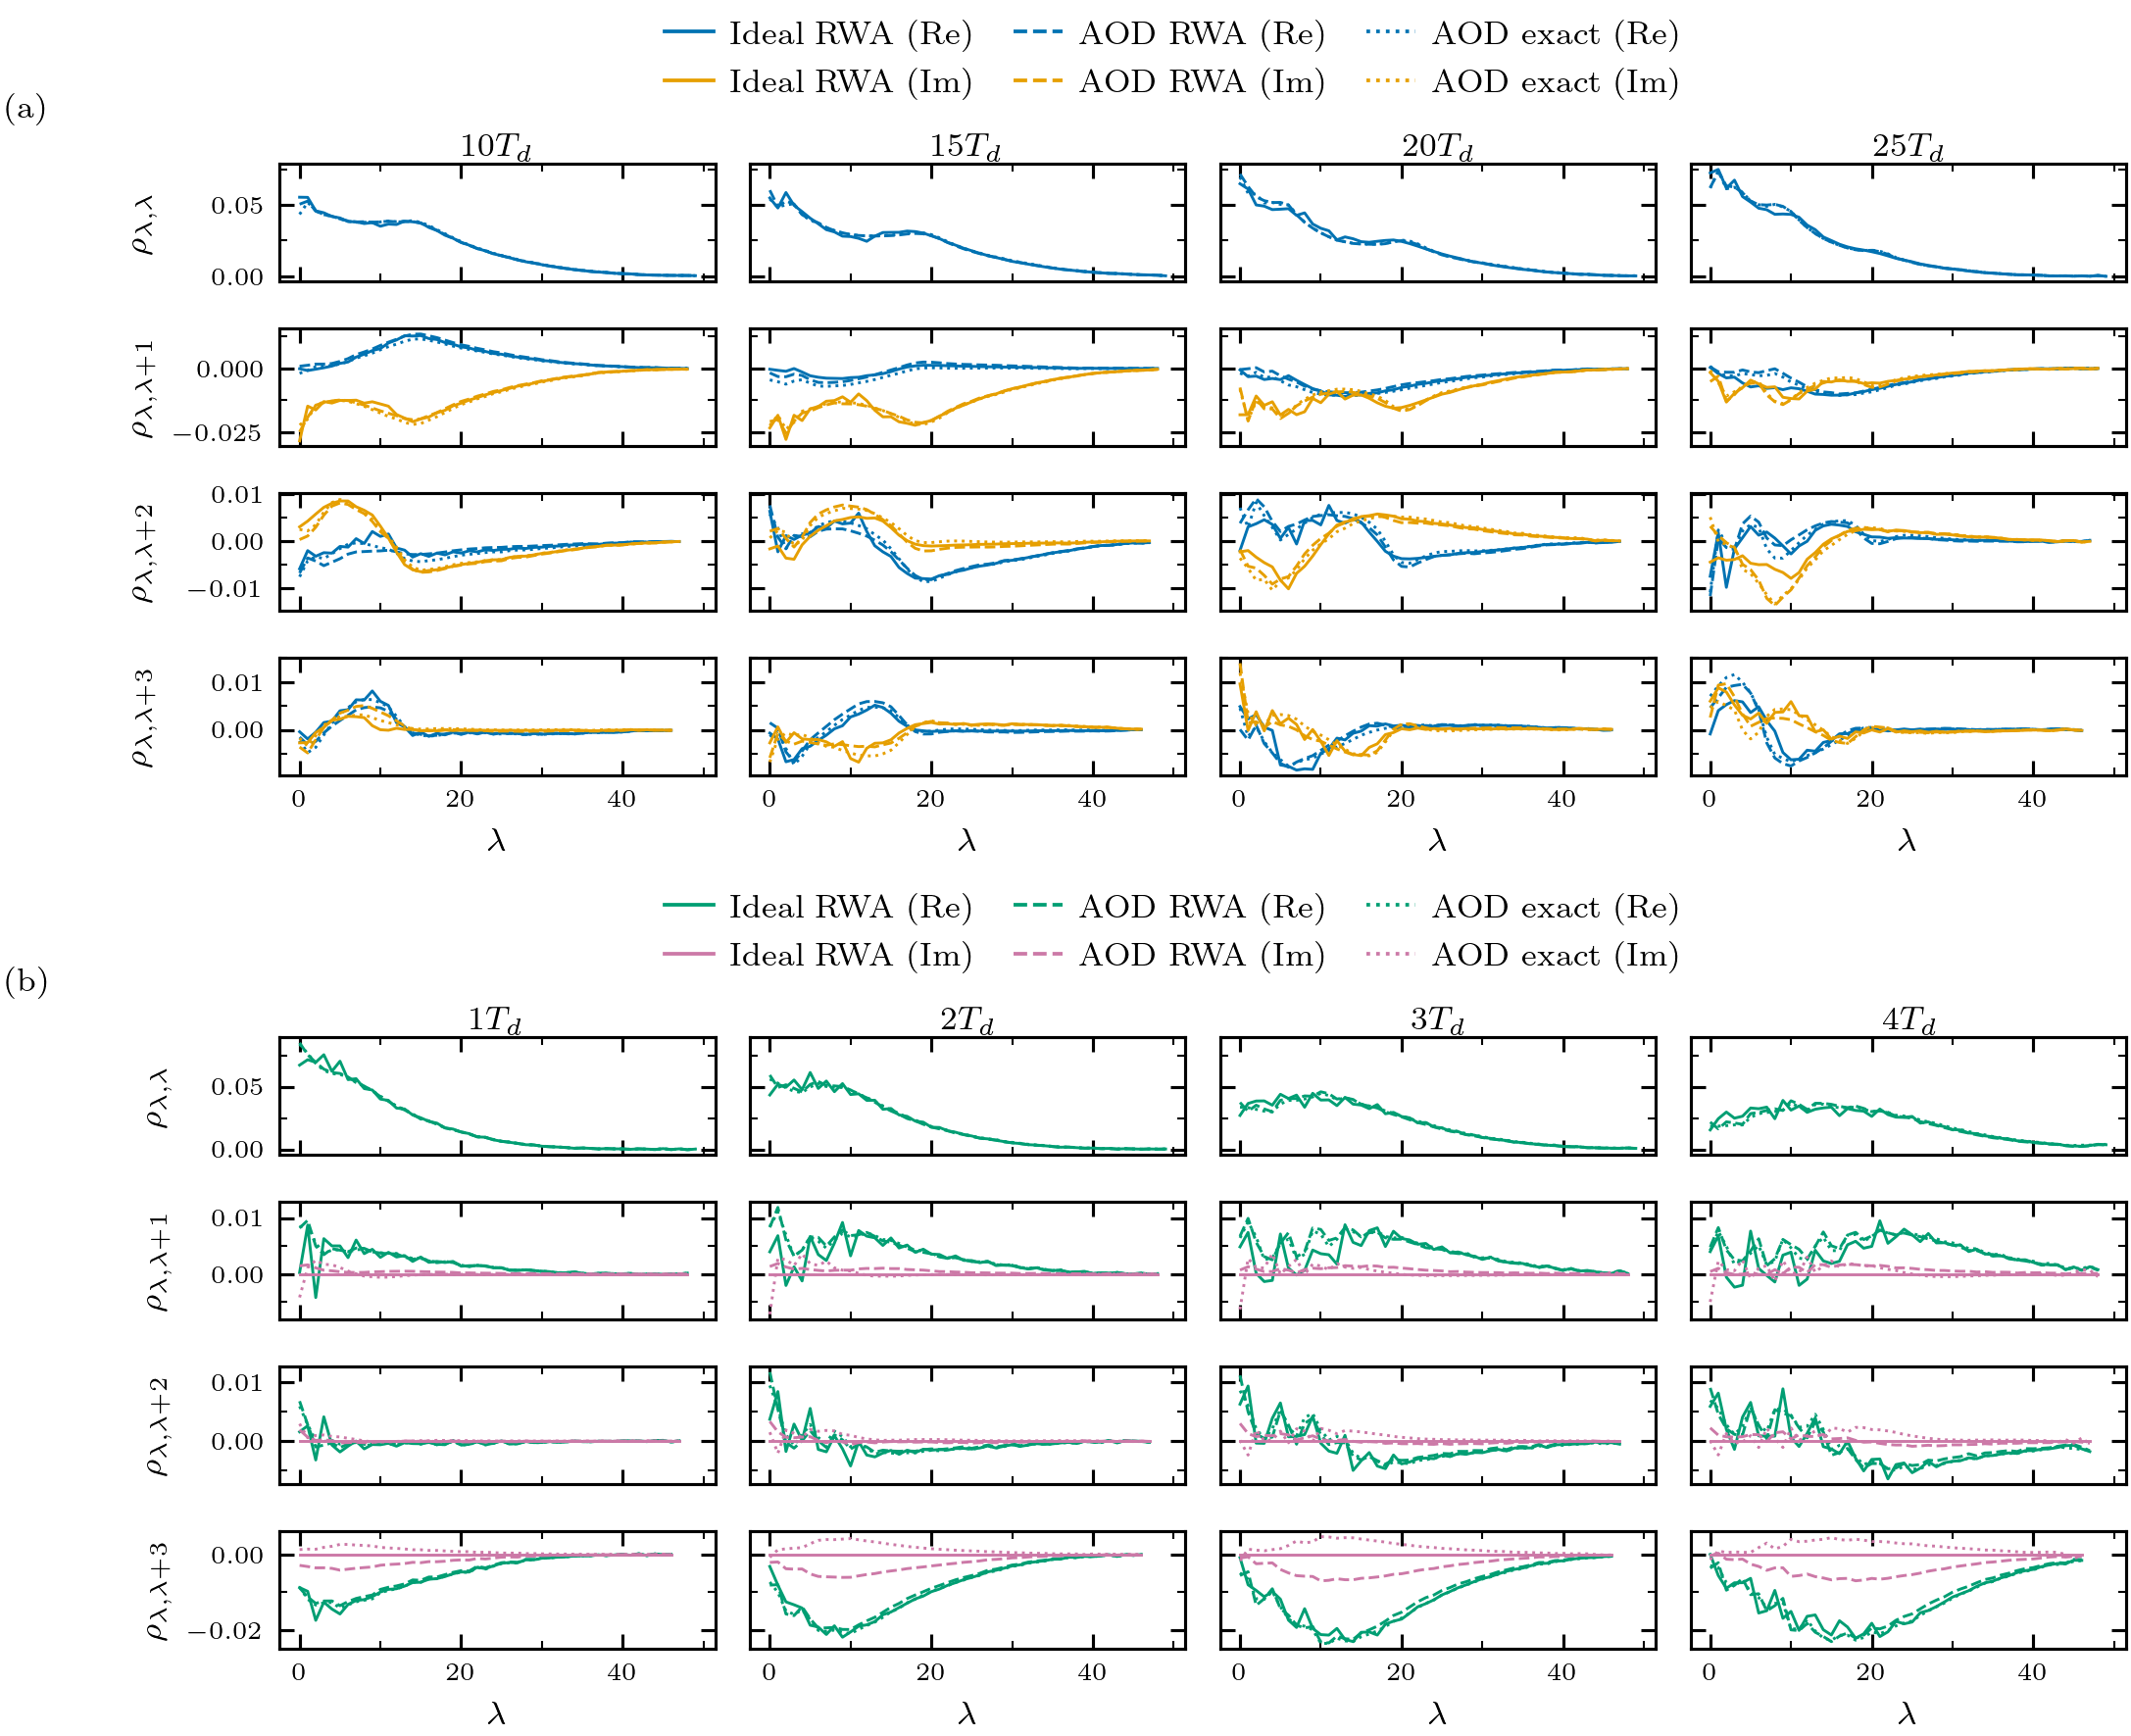

In [37]:
# ── Plot 4 — diagonal snapshots, panels (a) and (b) ─────────────────────────
SUBSET_NS = [[10, 15, 20, 25],[1,2,3,4]]
js       = range(4)
k        = 2
Ns       = len(SUBSET_NS[0])

# (mode-suffix, ic, jc)
modes = [("s", 0, 1), ("2", 2, 4)]

# load both datasets up front
datasets = {}
for mode, ic, jc in modes:
    datasets[mode] = _load(f"ideal_vs_AOD_{mode}d_iref{k}.npy")

from matplotlib.lines import Line2D

fig = plt.figure(figsize=(Ns * PRL_COL * 0.6, 4 * PRL_COL * 0.42))
subfigs = fig.subfigures(2, 1, hspace=0.1)

panel_labels = ["(a)", "(b)"]

for panel_idx, ((mode, ic, jc), subfig) in enumerate(zip(modes, subfigs)):
    rho_ideal     = datasets[mode][0]
    rho_ideal_aod = datasets[mode][1]
    rho_aod       = datasets[mode][2]
    site          = np.arange(rho_ideal.shape[1])

    axes = subfig.subplots(
        len(js), Ns,
        sharex=True, sharey="row",
    )
    subfig.subplots_adjust(hspace=0.4, wspace=0.08)

    
    legend_handles = [
        Line2D([0], [0], color=PALETTE[ic], lw=0.9, ls="-",  label=r"Ideal RWA (Re)"),
        Line2D([0], [0], color=PALETTE[jc], lw=0.9, ls="-",  label=r"Ideal RWA (Im)"),
        Line2D([0], [0], color=PALETTE[ic], lw=0.9, ls="--", label=r"AOD RWA (Re)"),
        Line2D([0], [0], color=PALETTE[jc], lw=0.9, ls="--", label=r"AOD RWA (Im)"),
        Line2D([0], [0], color=PALETTE[ic], lw=0.9, ls=":",  label=r"AOD exact (Re)"),
        Line2D([0], [0], color=PALETTE[jc], lw=0.9, ls=":",  label=r"AOD exact (Im)"),
    ]
    subfig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.1),   # push it further above the axes
        ncol=3,                        # two rows instead of one squished row
        fontsize=8,                    # was 5.5
        frameon=False,
        handlelength=1.5,
        columnspacing=1.2,
        handletextpad=0.5,
    )

    for col, n in enumerate(SUBSET_NS[panel_idx]):
        for row, j in enumerate(js):
            ax = axes[row, col]

            d_ideal     = np.real(np.diag(rho_ideal[n],     j))
            d_ideal_aod = np.real(np.diag(rho_ideal_aod[n], j))
            d_aod       = np.real(np.diag(rho_aod[n],       j))
            xs          = site[:len(d_ideal)]

            ax.plot(xs, d_ideal,     color=PALETTE[ic], lw=0.7, ls="-")
            ax.plot(xs, d_ideal_aod, color=PALETTE[ic], lw=0.7, ls="--")
            ax.plot(xs, d_aod,       color=PALETTE[ic], lw=0.7, ls=":")

            if j > 0:
                ax.plot(xs, np.imag(np.diag(rho_ideal[n],     j)),
                        color=PALETTE[jc], lw=0.7, ls="-")
                ax.plot(xs, np.imag(np.diag(rho_ideal_aod[n], j)),
                        color=PALETTE[jc], lw=0.7, ls="--")
                ax.plot(xs, np.imag(np.diag(rho_aod[n],       j)),
                        color=PALETTE[jc], lw=0.7, ls=":")

            if row == 0:
                ax.set_title(rf"${n}T_d$", fontsize=8, pad=2)
            if row == len(js) - 1:
                ax.set_xlabel(r"$\lambda$", fontsize=8)
            if col == 0:
                label = r"$\rho_{\lambda,\lambda}$" if j == 0 else rf"$\rho_{{\lambda,\lambda+{j}}}$"
                ax.set_ylabel(label, fontsize=8)

            ax.tick_params(labelsize=6)
            _ticks(ax)

    subfig.align_ylabels(axes[:, 0])

    # panel label top-left of each subfigure
    subfig.text(0.01, 0.97, panel_labels[panel_idx],
                fontsize=8, fontweight="bold",
                va="top", ha="left", transform=subfig.transSubfigure)

# single shared legend at the very top
# legend_handles = [
#     Line2D([0], [0], color="k", lw=0.7, ls="-",  label=r"RWA ideal"),
#     Line2D([0], [0], color="k", lw=0.7, ls="--", label=r"RWA AOD"),
#     Line2D([0], [0], color="k", lw=0.7, ls=":",  label=r"AOD exact"),
#     Line2D([0], [0], color=PALETTE[0], lw=0.7, ls="-", label=r""),
#     Line2D([0], [0], color=PALETTE[0], lw=0.7, ls="-", label=r"Re"),
#     Line2D([0], [0], color=PALETTE[1], lw=0.7, ls="-", label=r""),
#     Line2D([0], [0], color=PALETTE[1], lw=0.7, ls="-", label=r"Im"),

# ]
# fig.legend(
#     handles=legend_handles,
#     loc="upper center",
#     bbox_to_anchor=(0.5, 1.01),
#     ncol=5,
#     fontsize=5.5, frameon=False,
#     handlelength=1.2, columnspacing=0.8,
# )


_save(fig, f"plot4_diagonal_snapshots_iref{k}.pdf")
plt.show()